#### 1. Import Libaries

In [9]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Import torch/transformers FIRST
import torch
from transformers import pipeline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

#### 2. data loading

In [7]:
df = pd.read_csv("PSN_articles.csv")

print(df.shape)

df

(193, 7)


,title,source,published,google_link,url,text,text_for_sentiment
0,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...,Pontianak Post,2026-07-09 07:00:00+00:00,https://news.google.com/rss/articles/CBMi6wFBV...,https://pontianakpost.jawapos.com/ketapang/260...,NaN,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...
1,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...,Bisnis Tekno,2026-07-08 07:00:00+00:00,https://news.google.com/rss/articles/CBMiywFBV...,https://teknologi.bisnis.com/read/20260708/101...,NaN,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa...",Bisnis Tekno,2026-06-02 07:00:00+00:00,https://news.google.com/rss/articles/CBMizwFBV...,https://teknologi.bisnis.com/read/20260602/101...,NaN,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa..."
3,🛰️ Indonesia’s Nusantara Lima begins operation...,The Southeast Asia Desk,2026-05-19 07:00:00+00:00,https://news.google.com/rss/articles/CBMie0FVX...,https://www.thesoutheastasiadesk.com/p/indones...,🎯 The Main Takeaway\nIndonesia’s newest satell...,🎯 The Main Takeaway\nIndonesia’s newest satell...
4,Foto Bisnis SWA: Peresmian Operasional Satelit...,SWA.co.id,2026-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMilAFBV...,https://swa.co.id/read/472659/foto-bisnis-swa-...,Foto Bisnis SWA: Peresmian Operasional Satelit...,Foto Bisnis SWA: Peresmian Operasional Satelit...
...,...,...,...,...,...,...,...
188,PSN-6 satellite (SSL),Teslarati,2019-01-15 12:19:49+00:00,https://news.google.com/rss/articles/CBMitgFBV...,https://www.teslarati.com/spacex-falcon-9-luna...,Elon Musk just confirmed the Tesla and SpaceX ...,Elon Musk just confirmed the Tesla and SpaceX ...
189,PSN Siap Luncurkan Satelit PSN VI Berkapasitas...,CNN Indonesia,2017-12-07 08:00:00+00:00,https://news.google.com/rss/articles/CBMiuwFBV...,https://www.cnnindonesia.com/teknologi/2017120...,"Jakarta, CNN Indonesia -- PT Pasifik Satelit N...","Jakarta, CNN Indonesia -- PT Pasifik Satelit N..."
190,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit N...",JPNN.com,2017-05-22 07:00:00+00:00,https://news.google.com/rss/articles/CBMiqgFBV...,https://www.jpnn.com/news/bangun-satelit-palap...,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit N...","Bangun Satelit PALAPA-N1, PT Pasifik Satelit N..."
191,Indosat-PSN beli satelit Palapa-N1 dari perusa...,ANTARA News,2017-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMingFBV...,https://www.antaranews.com/berita/629703/indos...,Bisnis satelit itu bukan bisnis yang kita ngom...,Bisnis satelit itu bukan bisnis yang kita ngom...


#### 3. EDA

##### Dataframe info

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   title               193 non-null    object
 1   source              193 non-null    object
 2   published           193 non-null    object
 3   google_link         193 non-null    object
 4   url                 193 non-null    object
 5   text                160 non-null    object
 6   text_for_sentiment  193 non-null    object
dtypes: object(7)
memory usage: 10.7+ KB


In [5]:
df.isnull().sum()

title                  0
source                 0
published              0
google_link            0
url                    0
text                  33
text_for_sentiment     0
dtype: int64

##### Checking Duplicates

In [6]:
df["title"].str.lower().str.strip().duplicated().sum()

0

In [8]:
df["url"].duplicated().sum()

0

##### Dates of article published

In [ ]:
# converting time to datetime
df["published"] = pd.to_datetime(df["published"], utc=True)
df["year"] = df["published"].dt.year

In [21]:
# showing articles from oldest to newest
print(df["published"].min())
print(df["published"].max())

2017-05-17 07:00:00+00:00
2026-07-09 07:00:00+00:00


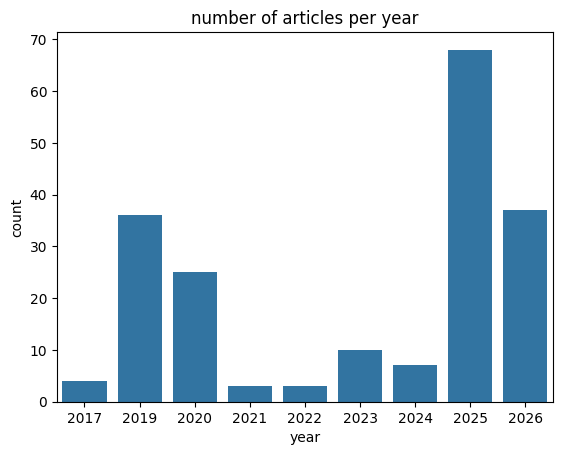

In [23]:
# number of articles per year
sns.countplot(data=df, x="year")
plt.title("number of articles per year")
plt.show()

##### Articles sources that dominates the most

In [26]:
print(df["source"].nunique())
df["source"].value_counts().head(10)

75


source
detikInet        34
Bisnis Tekno     13
Kompas.id        10
Suara.com        10
Tempo.co          9
Kumparan.com      9
ANTARA News       7
Kompas.com        6
InvestorTrust     5
kontan.co.id      4
Name: count, dtype: int64

##### The length of text 

count     193.0
mean      363.0
std       309.0
min         7.0
25%       124.0
50%       328.0
75%       511.0
max      1688.0
Name: word_count, dtype: float64


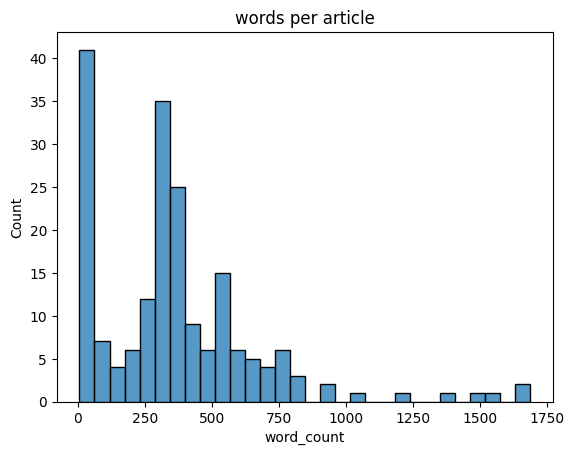

In [27]:
df["word_count"] = df["text_for_sentiment"].str.split().str.len()

print(df["word_count"].describe().round(0))

sns.histplot(data=df, x="word_count", bins=30)
plt.title("words per article")
plt.show()

here we can explore on how many articles that have only a title and how many that are fewer than 30 words from data scraping

In [28]:
print("title only:", df["text"].isnull().sum())

title only: 33


In [32]:
print("fewer than 30 words:", (df["word_count"] < 30).sum())

fewer than 30 words: 33


##### Finding what language the data dominates

In [33]:
first_part = df["text_for_sentiment"].str.lower().str[:500]
df["indo_words"] = first_part.str.count(r"\b(?:yang|dan|untuk|dengan|dari|pada|ini|satelit)\b")

df["language"] = np.where(df["indo_words"] >=3, "Indonesian", "English/other")

df["language"].value_counts()

language
Indonesian       141
English/other     52
Name: count, dtype: int64

##### Validating if the articles are about psn

In [34]:
keywords = "PSN|Pasifik Satelit|Pacific Satelite|Nusantara"
df["mentions_psn"] = df["text_for_sentiment"].str.contains(keywords, case=False, regex=True)

print(df["mentions_psn"].value_counts())

df[~df["mentions_psn"]][["title", "source"]]

mentions_psn
True     190
False      3
Name: count, dtype: int64


,title,source
37,Adi Rahman Adiwoso Raih Penghargaan Aerospace ...,Bisnis Tekno
127,"Adi Rahman Adiwoso, Teknologiwan Indonesia yan...",nukilan.id
188,PSN-6 satellite (SSL),Teslarati


#### 4. Data cleaning